# 11 — Vision-Language Foundations

## 1. Contrastive Vision-Language Learning

In the previous notebook, we explored visual tokens,
self-attention, and multimodal token fusion.

However, our text embeddings were randomly initialized.
The model had no understanding of the relationship between
language and visual observations.

In this notebook, we study how images and text can be
aligned in a shared embedding space.

### CLIP: Dual-Encoder Architecture

CLIP uses two separate encoders:

- An image encoder that extracts visual representations.
- A text encoder that extracts language representations.

Both representations are projected into a shared embedding
space and normalized.

$$
z_I = f_{\text{image}}(I)
$$

$$
z_T = f_{\text{text}}(T)
$$

$$
\hat{z}_I = \frac{z_I}{\|z_I\|},
\qquad
\hat{z}_T = \frac{z_T}{\|z_T\|}
$$

Their similarity is computed using the dot product:

$$
s(I,T) = \hat{z}_I^\top \hat{z}_T
$$

Contrastive training encourages matching image-text pairs
to have higher similarity than mismatched pairs.

We will first explore a pretrained CLIP model, then
investigate the contrastive learning objective.

In [8]:
import torch
import numpy as np
import matplotlib.pyplot as plt

from PIL import Image
from transformers import CLIPModel, CLIPProcessor

device = torch.device(
    "mps" if torch.backends.mps.is_available() else "cpu"
)

model_id = "openai/clip-vit-base-patch32"

clip_model = CLIPModel.from_pretrained(model_id).to(device)
clip_processor = CLIPProcessor.from_pretrained(model_id)

clip_model.eval()

print("Device:", device)
print("Image encoder:", clip_model.config.vision_config.model_type)
print("Text encoder:", clip_model.config.text_config.model_type)
print("Shared embedding dimension:", clip_model.config.projection_dim)

Loading weights: 100%|██████████| 398/398 [00:00<00:00, 49209.47it/s]


Device: mps
Image encoder: clip_vision_model
Text encoder: clip_text_model
Shared embedding dimension: 512


## 2. Image-Text Similarity

We now use pretrained CLIP to compare a PushT observation
with several natural-language descriptions.

CLIP independently encodes the image and each text prompt
into a shared 512-dimensional embedding space.

We compute cosine similarities between the normalized
embeddings and rank the candidate descriptions.

This is a simple form of zero-shot image-text matching:
no PushT-specific training is performed.

Fetching 4 files: 100%|██████████| 4/4 [00:00<00:00, 1288.67it/s]


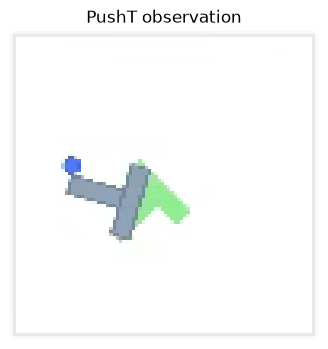

In [9]:
from lerobot.datasets.lerobot_dataset import LeRobotDataset

dataset = LeRobotDataset("lerobot/pusht")

sample = dataset[100]
image_tensor = sample["observation.image"]

image = Image.fromarray(
    (
        image_tensor.permute(1, 2, 0).numpy() * 255
    ).clip(0, 255).astype(np.uint8)
)

plt.figure(figsize=(4, 4))
plt.imshow(image)
plt.title("PushT observation")
plt.axis("off")
plt.show()

In [10]:
texts = [
    "A blue circular robot next to a gray T-shaped block.",
    "A robot pushing an object on a white table.",
    "A dog running through a green park.",
    "A red car driving along a road.",
]

inputs = clip_processor(
    text=texts,
    images=image,
    return_tensors="pt",
    padding=True,
).to(device)

with torch.no_grad():
    image_features = clip_model.get_image_features(
        pixel_values=inputs["pixel_values"]
    )

    text_features = clip_model.get_text_features(
        input_ids=inputs["input_ids"],
        attention_mask=inputs["attention_mask"],
    )

    # Transformers versions may return an output object
    # rather than a raw tensor.
    if hasattr(image_features, "pooler_output"):
        image_features = image_features.pooler_output

    if hasattr(text_features, "pooler_output"):
        text_features = text_features.pooler_output

    image_features = torch.nn.functional.normalize(
        image_features, dim=-1
    )

    text_features = torch.nn.functional.normalize(
        text_features, dim=-1
    )

    similarities = image_features @ text_features.T

scores = similarities[0].cpu().numpy()

print("Image embedding:", image_features.shape)
print("Text embeddings:", text_features.shape)
print("Similarity scores:", scores.shape)

for idx in np.argsort(scores)[::-1]:
    print(f"{scores[idx]:+.4f} | {texts[idx]}")

Image embedding: torch.Size([1, 512])
Text embeddings: torch.Size([4, 512])
Similarity scores: (4,)
+0.2620 | A blue circular robot next to a gray T-shaped block.
+0.2304 | A robot pushing an object on a white table.
+0.1722 | A dog running through a green park.
+0.1517 | A red car driving along a road.


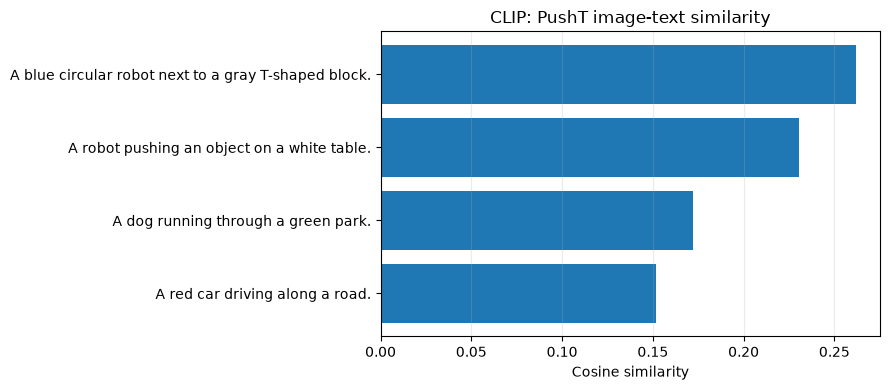

In [6]:
order = np.argsort(scores)

plt.figure(figsize=(9, 4))

plt.barh(
    [texts[i] for i in order],
    scores[order],
)

plt.xlabel("Cosine similarity")
plt.title("CLIP: PushT image-text similarity")
plt.grid(axis="x", alpha=0.25)
plt.tight_layout()
plt.show()

## 3. Contrastive Learning: InfoNCE

CLIP learns image-text alignment through contrastive learning.

Given a batch of matching image-text pairs, the model
computes a similarity matrix between all image embeddings
and all text embeddings.

$$
S_{ij} = \hat{z}_{I_i}^{\top}\hat{z}_{T_j}
$$

The diagonal contains positive pairs, while off-diagonal
entries are treated as negative pairs.

The image-to-text contrastive loss is:

$$
\mathcal{L}_{I \rightarrow T}
=
-\frac{1}{B}
\sum_{i=1}^{B}
\log
\frac{\exp(S_{ii}/\tau)}
{\sum_j \exp(S_{ij}/\tau)}
$$

CLIP also computes the symmetric text-to-image loss.

$$
\mathcal{L}
=
\frac{1}{2}
\left(
\mathcal{L}_{I \rightarrow T}
+
\mathcal{L}_{T \rightarrow I}
\right)
$$

The objective encourages matching image-text pairs
to have higher similarity than mismatched pairs.

In [7]:
import torch.nn.functional as F

def clip_contrastive_loss(image_embeds, text_embeds, temperature=0.07):
    image_embeds = F.normalize(image_embeds, dim=-1)
    text_embeds = F.normalize(text_embeds, dim=-1)

    logits = image_embeds @ text_embeds.T / temperature

    labels = torch.arange(
        image_embeds.shape[0],
        device=image_embeds.device,
    )

    loss_i2t = F.cross_entropy(logits, labels)
    loss_t2i = F.cross_entropy(logits.T, labels)

    return 0.5 * (loss_i2t + loss_t2i), logits


torch.manual_seed(42)

B = 4
D = 512

# Four random image embeddings
synthetic_images = torch.randn(B, D, device=device)

# Matching text embeddings: same signal + small noise
synthetic_texts = (
    synthetic_images
    + 0.2 * torch.randn(B, D, device=device)
)

# Mismatched text embeddings: independent random vectors
random_texts = torch.randn(B, D, device=device)

loss_matching, logits_matching = clip_contrastive_loss(
    synthetic_images, synthetic_texts
)

loss_random, logits_random = clip_contrastive_loss(
    synthetic_images, random_texts
)

print(f"Matching pairs loss: {loss_matching.item():.4f}")
print(f"Random pairs loss:   {loss_random.item():.4f}")
print(f"Random baseline:     {np.log(B):.4f}")

Matching pairs loss: 0.0000
Random pairs loss:   1.3650
Random baseline:     1.3863


### 3.2 Visualizing the Contrastive Similarity Matrix

The contrastive objective operates on a batch-wise
image-text similarity matrix.

For a batch of size B, the matrix has shape B × B.

Each row compares one image against all candidate texts.
Each column compares one text against all candidate images.

The diagonal contains matching pairs.

We compare the similarity matrices of matching and
randomly paired synthetic embeddings.

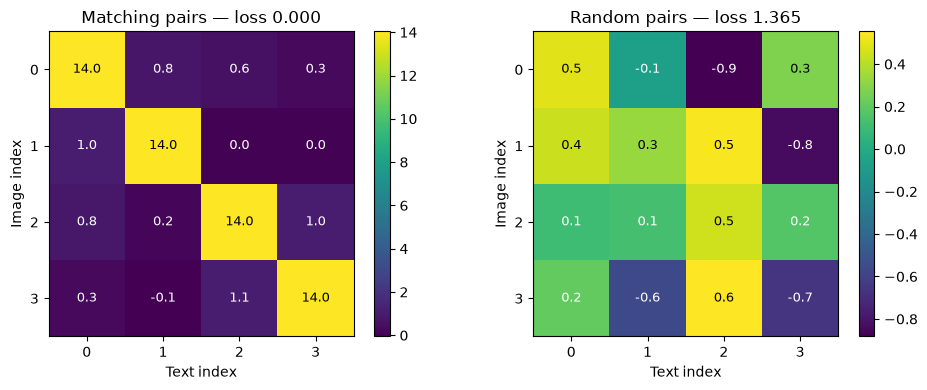

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4))

matrices = [
    logits_matching.detach().cpu().numpy(),
    logits_random.detach().cpu().numpy(),
]

titles = [
    f"Matching pairs — loss {loss_matching.item():.3f}",
    f"Random pairs — loss {loss_random.item():.3f}",
]

for ax, matrix, title in zip(axes, matrices, titles):
    im = ax.imshow(matrix, cmap="viridis")

    ax.set_title(title)
    ax.set_xlabel("Text index")
    ax.set_ylabel("Image index")

    ax.set_xticks(range(B))
    ax.set_yticks(range(B))

    for i in range(B):
        for j in range(B):
            ax.text(
                j, i, f"{matrix[i, j]:.1f}",
                ha="center", va="center",
                color="white" if matrix[i, j] < matrix.max() * 0.5 else "black",
                fontsize=9,
            )

    plt.colorbar(im, ax=ax, fraction=0.046)

plt.tight_layout()
plt.show()

## 4. Real Image-Text Similarity Matrices

We now construct a similarity matrix using pretrained CLIP.

Unlike our synthetic experiment, real images may share
similar objects, backgrounds, and spatial configurations.

Therefore, different images can have similar language
descriptions, and the diagonal is not guaranteed to
contain the highest scores.

This experiment illustrates both the usefulness and
limitations of global image-text embeddings for robotics.

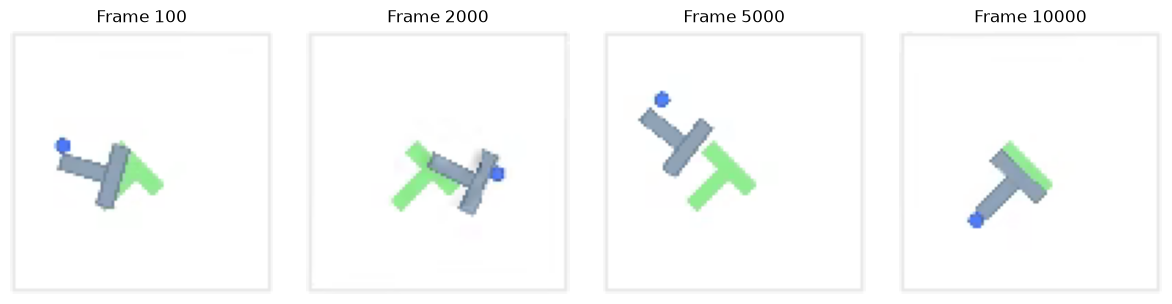

In [9]:
sample_indices = [100, 2000, 5000, 10000]

pusht_images = []

for idx in sample_indices:
    tensor = dataset[idx]["observation.image"]

    array = (
        tensor.permute(1, 2, 0).numpy() * 255
    ).clip(0, 255).astype(np.uint8)

    pusht_images.append(Image.fromarray(array))

fig, axes = plt.subplots(1, 4, figsize=(12, 3))

for ax, img, idx in zip(axes, pusht_images, sample_indices):
    ax.imshow(img)
    ax.set_title(f"Frame {idx}")
    ax.axis("off")

plt.tight_layout()
plt.show()

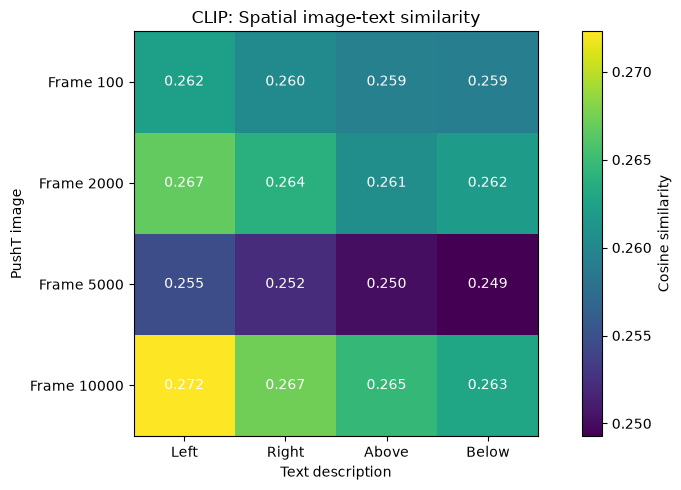

In [10]:
spatial_descriptions = [
    "A blue circular robot to the left of a gray T-shaped block.",
    "A blue circular robot to the right of a gray T-shaped block.",
    "A blue circular robot above a gray T-shaped block.",
    "A blue circular robot below a gray T-shaped block.",
]

inputs = clip_processor(
    images=pusht_images,
    text=spatial_descriptions,
    return_tensors="pt",
    padding=True,
).to(device)

with torch.no_grad():
    outputs = clip_model(**inputs)

    # CLIP's projected, normalized embeddings
    image_embeds = F.normalize(outputs.image_embeds, dim=-1)
    text_embeds = F.normalize(outputs.text_embeds, dim=-1)

    similarity_matrix = image_embeds @ text_embeds.T

similarity_np = similarity_matrix.cpu().numpy()

plt.figure(figsize=(9, 5))

im = plt.imshow(similarity_np, cmap="viridis")

plt.xticks(
    range(4),
    ["Left", "Right", "Above", "Below"],
)
plt.yticks(
    range(4),
    [f"Frame {i}" for i in sample_indices],
)

plt.xlabel("Text description")
plt.ylabel("PushT image")
plt.title("CLIP: Spatial image-text similarity")

for i in range(4):
    for j in range(4):
        plt.text(
            j, i, f"{similarity_np[i, j]:.3f}",
            ha="center", va="center",
            color="white",
        )

plt.colorbar(im, label="Cosine similarity")
plt.tight_layout()
plt.show()

### 4.1 Diagnosing Spatial Language Embeddings

The previous experiment showed that CLIP consistently
preferred the same spatial description across different
PushT images.

We now examine the text embeddings directly.

If the four spatial descriptions produce highly similar
embeddings, their differences may be small compared to
the shared semantic content.

We compute a text-to-text cosine similarity matrix to
investigate how strongly CLIP distinguishes the prompts.

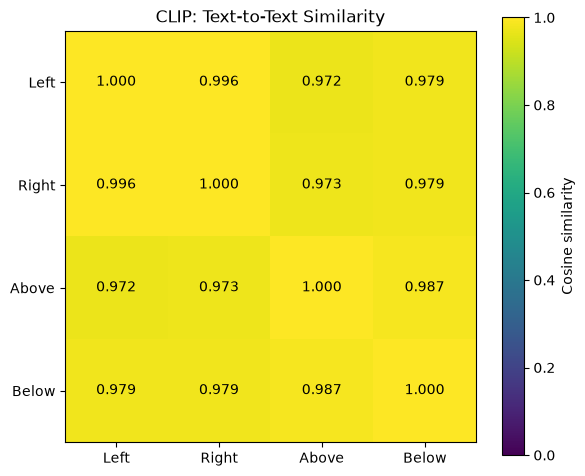

In [11]:
# Reuse text_embeds from Step 4
text_similarity = text_embeds @ text_embeds.T

text_similarity_np = text_similarity.cpu().numpy()

plt.figure(figsize=(6, 5))

plt.imshow(
    text_similarity_np,
    cmap="viridis",
    vmin=0,
    vmax=1,
)

labels = ["Left", "Right", "Above", "Below"]

plt.xticks(range(4), labels)
plt.yticks(range(4), labels)

for i in range(4):
    for j in range(4):
        plt.text(
            j, i,
            f"{text_similarity_np[i, j]:.3f}",
            ha="center",
            va="center",
            color="white" if text_similarity_np[i, j] < 0.5 else "black",
        )

plt.colorbar(label="Cosine similarity")
plt.title("CLIP: Text-to-Text Similarity")
plt.tight_layout()
plt.show()

## 5. From CLIP to Generative Vision-Language Models

CLIP learns a shared embedding space for images and text.

However, global embedding similarity does not directly
provide detailed visual reasoning or language generation.

Generative Vision-Language Models introduce additional
components that connect visual representations to a
language model.

A common architecture contains:

1. A visual encoder that extracts image features.
2. A multimodal projector that maps visual features
   into the language model's embedding space.
3. A language model that processes visual context and
   generates text autoregressively.

This architecture differs from CLIP's dual-encoder
contrastive approach.

## 6. Connecting Visual Tokens to a Language Model

CLIP aligns global image and text embeddings through
contrastive learning.

Generative Vision-Language Models take a different approach:
they condition a language model on visual information.

A common architecture consists of:

1. A vision encoder that extracts visual tokens.
2. A multimodal projector that maps visual features into
   the language model's embedding space.
3. A language model that processes visual and text tokens
   to generate a response.

The vision encoder produces:

$$
V \in \mathbb{R}^{B \times N_v \times d_v}
$$

The language model operates with hidden dimension
$d_{\text{LLM}}$.

A projector maps visual tokens into the language model's
representation space:

$$
V' = P(V)
$$

$$
V' \in \mathbb{R}^{B \times N_v \times d_{\text{LLM}}}
$$

The projected visual tokens can then be combined with
language token embeddings.

We first implement this mechanism using a small,
untrained multimodal projector.

In [5]:
import torch
import torch.nn as nn

# Reuse the pretrained CLIP model and image from previous steps

vision_encoder = clip_model.vision_model

vision_dim = clip_model.config.vision_config.hidden_size
llm_dim = 512

print("Vision hidden dimension:", vision_dim)
print("Simulated LLM dimension:", llm_dim)

class MultimodalProjector(nn.Module):
    def __init__(self, vision_dim, llm_dim):
        super().__init__()

        self.net = nn.Sequential(
            nn.Linear(vision_dim, llm_dim),
            nn.GELU(),
            nn.Linear(llm_dim, llm_dim),
        )

    def forward(self, visual_tokens):
        return self.net(visual_tokens)


projector = MultimodalProjector(
    vision_dim=vision_dim,
    llm_dim=llm_dim,
).to(device)

# Preprocess one PushT image
pixel_inputs = clip_processor(
    images=image,
    return_tensors="pt",
).to(device)

vision_encoder.eval()

with torch.no_grad():
    vision_outputs = vision_encoder(
        pixel_values=pixel_inputs["pixel_values"]
    )

    visual_tokens = vision_outputs.last_hidden_state

    projected_tokens = projector(visual_tokens)

print("Visual tokens:", visual_tokens.shape)
print("Projected tokens:", projected_tokens.shape)

Vision hidden dimension: 768
Simulated LLM dimension: 512
Visual tokens: torch.Size([1, 50, 768])
Projected tokens: torch.Size([1, 50, 512])


50 token: ViT receive 224x224 image and divided in 49 patches + 1 CLS token for global representation

Actually CLIP is using vision encoder (50 token, dim 768) + projector layer for CLS token (768->512)

In [12]:
with torch.no_grad():
    vision_outputs = clip_model.vision_model(
        pixel_values=pixel_inputs["pixel_values"]
    )

    # All visual tokens
    all_tokens = vision_outputs.last_hidden_state

    # Global representation (CLS after final LayerNorm)
    pooled = vision_outputs.pooler_output

    # CLIP's pretrained projection
    projected_global = clip_model.visual_projection(pooled)

    # Compare with the complete CLIP image encoder
    clip_features = clip_model.get_image_features(
        pixel_values=pixel_inputs["pixel_values"]
    )
    # Transformers versions may return an output object
    # rather than a raw tensor.
    if hasattr(clip_features, "pooler_output"):
        clip_features = clip_features.pooler_output

print("All visual tokens:", all_tokens.shape)
print("Pooled CLS:", pooled.shape)
print("Projected global embedding:", projected_global.shape)
print("CLIP image features:", clip_features.shape)

print(
    "Projection difference:",
    (projected_global - clip_features).abs().max().item()
)

All visual tokens: torch.Size([1, 50, 768])
Pooled CLS: torch.Size([1, 768])
Projected global embedding: torch.Size([1, 512])
CLIP image features: torch.Size([1, 512])
Projection difference: 0.0


### 6.3 Building a Multimodal Input Sequence

A language model normally processes a sequence of
text token embeddings.

To condition generation on an image, some VLM
architectures insert projected visual tokens into
the language model's input sequence.

Let:

$$
V' \in \mathbb{R}^{B \times N_v \times d_{\text{LLM}}}
$$

represent projected visual tokens, and:

$$
T \in \mathbb{R}^{B \times N_t \times d_{\text{LLM}}}
$$

represent text token embeddings.

We concatenate both sequences:

$$
X = [V'; T]
$$

The resulting sequence contains both visual and
linguistic information.

In this experiment, we use a small randomly initialized
text embedding layer to study the mechanism.

This is not yet a pretrained generative VLM.

In [13]:
question = "where is the blue robot relative to the gray block"

words = question.split()

vocab = {
    word: idx + 1
    for idx, word in enumerate(sorted(set(words)))
}

vocab["<pad>"] = 0

token_ids = torch.tensor(
    [[vocab[word] for word in words]],
    device=device,
)

text_embedding = nn.Embedding(
    num_embeddings=len(vocab),
    embedding_dim=llm_dim,
).to(device)

text_tokens = text_embedding(token_ids)

print("Question:", question)
print("Token IDs:", token_ids.shape)
print("Text tokens:", text_tokens.shape)

Question: where is the blue robot relative to the gray block
Token IDs: torch.Size([1, 10])
Text tokens: torch.Size([1, 10, 512])


In [14]:
multimodal_tokens = torch.cat(
    [projected_tokens, text_tokens],
    dim=1,
)

print("Visual tokens:", projected_tokens.shape)
print("Text tokens:", text_tokens.shape)
print("Multimodal sequence:", multimodal_tokens.shape)

Visual tokens: torch.Size([1, 50, 512])
Text tokens: torch.Size([1, 10, 512])
Multimodal sequence: torch.Size([1, 60, 512])


In [15]:
modality_embedding = nn.Embedding(
    num_embeddings=2,
    embedding_dim=llm_dim,
).to(device)

n_visual = projected_tokens.shape[1]
n_text = text_tokens.shape[1]

modality_ids = torch.cat(
    [
        torch.zeros(n_visual, dtype=torch.long),
        torch.ones(n_text, dtype=torch.long),
    ]
).unsqueeze(0).to(device)

multimodal_tokens = (
    multimodal_tokens
    + modality_embedding(modality_ids)
)

print("Modality IDs:", modality_ids.shape)
print("Final multimodal sequence:", multimodal_tokens.shape)

print(
    "First 10 modality IDs:",
    modality_ids[0, :10].tolist()
)

print(
    "Last 10 modality IDs:",
    modality_ids[0, -10:].tolist()
)

Modality IDs: torch.Size([1, 60])
Final multimodal sequence: torch.Size([1, 60, 512])
First 10 modality IDs: [0, 0, 0, 0, 0, 0, 0, 0, 0, 0]
Last 10 modality IDs: [1, 1, 1, 1, 1, 1, 1, 1, 1, 1]


## 7. Causal Self-Attention for Multimodal Generation

In a Vision Transformer, self-attention typically allows
every visual token to attend to every other visual token.

Autoregressive language models use causal self-attention:
each token can attend only to itself and previous tokens.

The attention operation becomes:

$$
\operatorname{Attention}(Q,K,V)
=
\operatorname{softmax}
\left(
\frac{QK^\top}{\sqrt{d_k}} + M
\right)V
$$

where the causal mask is:

$$
M_{ij} =
\begin{cases}
0 & j \leq i \\
-\infty & j > i
\end{cases}
$$

By placing visual tokens before text tokens, a text token
can attend to the visual context and preceding text.

We will visualize this mechanism using our existing
multimodal token sequence.

Causal mask shape: torch.Size([60, 60])


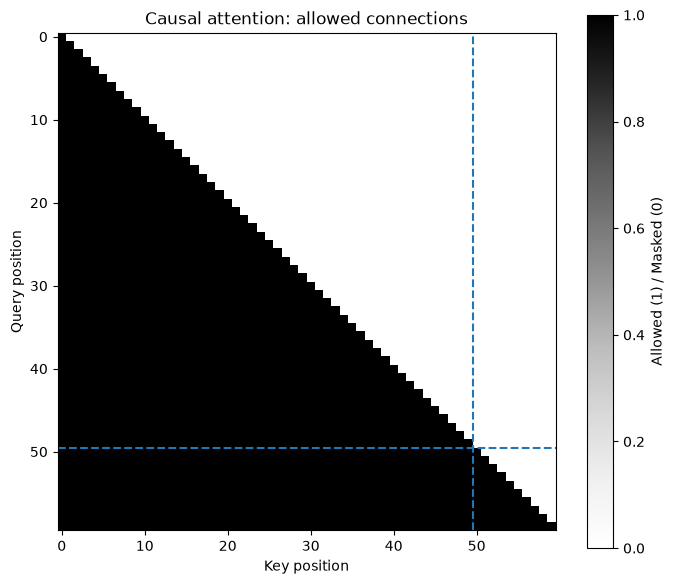

In [16]:
import torch
import torch.nn as nn
import matplotlib.pyplot as plt

seq_len = multimodal_tokens.shape[1]

causal_mask = torch.triu(
    torch.ones(
        seq_len,
        seq_len,
        dtype=torch.bool,
        device=device,
    ),
    diagonal=1,
)

print("Causal mask shape:", causal_mask.shape)

plt.figure(figsize=(7, 6))

plt.imshow(
    (~causal_mask).cpu().numpy(),
    cmap="Greys",
    vmin=0,
    vmax=1,
    origin="upper",
)

plt.axvline(49.5, color="tab:blue", linestyle="--")
plt.axhline(49.5, color="tab:blue", linestyle="--")

plt.xlabel("Key position")
plt.ylabel("Query position")
plt.title("Causal attention: allowed connections")

plt.colorbar(label="Allowed (1) / Masked (0)")
plt.tight_layout()
plt.show()

In [17]:
causal_attention = nn.MultiheadAttention(
    embed_dim=llm_dim,
    num_heads=8,
    batch_first=True,
).to(device)

causal_attention.eval()

with torch.no_grad():
    causal_output, causal_weights = causal_attention(
        multimodal_tokens,
        multimodal_tokens,
        multimodal_tokens,
        attn_mask=causal_mask,
        need_weights=True,
        average_attn_weights=False,
    )

print("Input:", multimodal_tokens.shape)
print("Output:", causal_output.shape)
print("Attention weights:", causal_weights.shape)

Input: torch.Size([1, 60, 512])
Output: torch.Size([1, 60, 512])
Attention weights: torch.Size([1, 8, 60, 60])


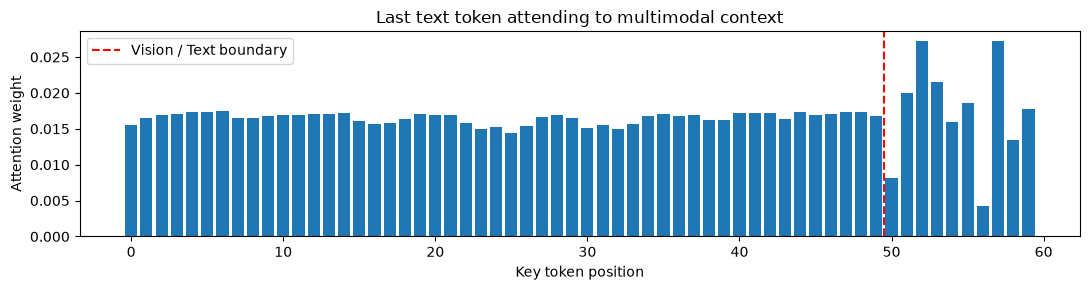

Attention to visual tokens: 0.8259746
Attention to text tokens: 0.17402545


In [18]:
attention_map = (
    causal_weights[0, 0, -1]
    .detach()
    .cpu()
    .numpy()
)

plt.figure(figsize=(11, 3))

plt.bar(range(seq_len), attention_map)

plt.axvline(
    n_visual - 0.5,
    color="red",
    linestyle="--",
    label="Vision / Text boundary",
)

plt.xlabel("Key token position")
plt.ylabel("Attention weight")
plt.title("Last text token attending to multimodal context")
plt.legend()
plt.tight_layout()
plt.show()

print(
    "Attention to visual tokens:",
    attention_map[:n_visual].sum()
)

print(
    "Attention to text tokens:",
    attention_map[n_visual:].sum()
)

## 8. Inference with a Pretrained Vision-Language Model

We have explored the main components of a generative VLM:

- Visual token extraction
- Multimodal projection
- Visual and text token fusion
- Causal self-attention

We now move from randomly initialized components to
a pretrained Vision-Language Model.

Our goal is to evaluate whether the model can:

1. Describe a PushT scene.
2. Identify the robot and the block.
3. Reason about their relative spatial positions.

We will compare its responses with the spatial
grounding limitations observed in CLIP.

This is an inference experiment: no training is required.

In [19]:
import torch
from transformers import AutoProcessor, AutoModelForImageTextToText

vlm_id = "HuggingFaceTB/SmolVLM-256M-Instruct"

vlm_processor = AutoProcessor.from_pretrained(vlm_id)

vlm = AutoModelForImageTextToText.from_pretrained(
    vlm_id,
    torch_dtype=torch.float32,
).to(device)

vlm.eval()

print("VLM loaded on:", next(vlm.parameters()).device)

[transformers] Model config: pad_token_id must be `None` or an integer within the vocabulary (between 0 and 31999), got 128002. This may result in unexpected behavior.
[transformers] `torch_dtype` is deprecated! Use `dtype` instead!
Loading weights: 100%|██████████| 471/471 [00:00<00:00, 1808.12it/s]


VLM loaded on: mps:0


In [29]:
question = "Describe the objects visible in this image."

messages = [
    {
        "role": "user",
        "content": [
            {"type": "image"},
            {"type": "text", "text": question},
        ],
    }
]

prompt = vlm_processor.apply_chat_template(
    messages,
    add_generation_prompt=True,
)
print("Prompt:", prompt)
print('\nInputs:')

inputs = vlm_processor(
    text=prompt,
    images=[image],
    return_tensors="pt",
).to(device)

for key, value in inputs.items():
    if isinstance(value, torch.Tensor):
        print(key, value.shape, value.dtype)
    else:
        print(key, type(value))

with torch.inference_mode():
    generated_ids = vlm.generate(
        **inputs,
        max_new_tokens=200,
        do_sample=False,
    )

new_tokens = generated_ids[:, inputs["input_ids"].shape[1]:]

answer = vlm_processor.batch_decode(
    new_tokens,
    skip_special_tokens=True,
)[0]

print("\nQuestion:", question)
print("Answer:", answer)

Prompt: <|im_start|>User:<image>Describe the objects visible in this image.<end_of_utterance>
Assistant:

Inputs:
input_ids torch.Size([1, 1143]) torch.int64
attention_mask torch.Size([1, 1143]) torch.int64
pixel_values torch.Size([1, 17, 3, 512, 512]) torch.float32
pixel_attention_mask torch.Size([1, 17, 512, 512]) torch.int64

Question: Describe the objects visible in this image.
Answer:  The image depicts a rectangular shape with a blue dot positioned in the upper left corner. The shape appears to be a square, with a single blue dot positioned in the upper left corner. The square shape is filled with a light gray color, and the blue dot is a solid blue color. The shape is simple and straightforward, with no additional details or additional shapes.

The image does not contain any text, numbers, or other objects that would typically be found in a geometric shape. The shape is a simple, flat representation of a square, and it does not have any additional details or additional shapes.



In [28]:
# ** unpack dictionary into function arguments
def somma(a, b):
    return a + b

valori = {"a": 3, "b": 5}

print(somma(**valori))  # 8

8


In [30]:
print("Text attention mask:")
print(inputs["attention_mask"].shape)
print(torch.unique(inputs["attention_mask"]))

print("\nPixel attention mask:")
print(inputs["pixel_attention_mask"].shape)
print(torch.unique(inputs["pixel_attention_mask"]))

Text attention mask:
torch.Size([1, 1143])
tensor([1], device='mps:0')

Pixel attention mask:
torch.Size([1, 17, 512, 512])
tensor([1], device='mps:0')


### 8.2 Evaluating Spatial Understanding

In the previous CLIP experiment, we compared image-text
similarities for four spatial descriptions:

- Left of the block
- Right of the block
- Above the block
- Below the block

CLIP showed limited discrimination between these
spatial relationships.

We now evaluate a pretrained generative VLM on the
same PushT frames.

Unlike CLIP, which assigns similarity scores to
candidate descriptions, a generative VLM produces
an answer autoregressively.

We use a constrained question to simplify evaluation:

"Where is the blue circular robot relative to the
gray T-shaped block?"

The model must choose one of four directions.

This experiment evaluates zero-shot spatial reasoning
on synthetic robotic observations.

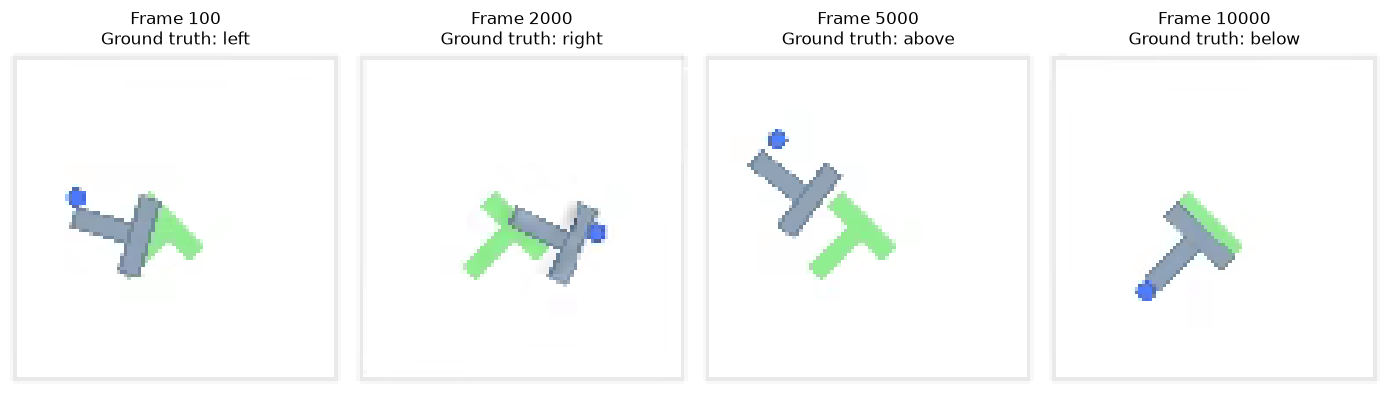

In [31]:
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image

sample_indices = [100, 2000, 5000, 10000]
ground_truth = ["left", "right", "above", "below"]

def pusht_image(index):
    sample = dataset[index]

    image_tensor = sample["observation.image"]

    image_array = (
        image_tensor.permute(1, 2, 0)
        .cpu()
        .numpy()
    )

    image_array = (
        image_array * 255
    ).clip(0, 255).astype(np.uint8)

    return Image.fromarray(image_array)


test_images = [
    pusht_image(idx)
    for idx in sample_indices
]

fig, axes = plt.subplots(1, 4, figsize=(14, 4))

for ax, img, idx, label in zip(
    axes, test_images, sample_indices, ground_truth
):
    ax.imshow(img)
    ax.set_title(f"Frame {idx}\nGround truth: {label}")
    ax.axis("off")

plt.tight_layout()
plt.show()

In [32]:
def ask_vlm(image, question, max_new_tokens=40):
    messages = [
        {
            "role": "user",
            "content": [
                {"type": "image"},
                {"type": "text", "text": question},
            ],
        }
    ]

    prompt = vlm_processor.apply_chat_template(
        messages,
        add_generation_prompt=True,
    )

    inputs = vlm_processor(
        text=prompt,
        images=[image],
        return_tensors="pt",
    ).to(device)

    with torch.inference_mode():
        generated_ids = vlm.generate(
            **inputs,
            max_new_tokens=max_new_tokens,
            do_sample=False,
        )

    new_tokens = generated_ids[
        :, inputs["input_ids"].shape[1]:
    ]

    answer = vlm_processor.batch_decode(
        new_tokens,
        skip_special_tokens=True,
    )[0]

    return answer.strip()

In [33]:
spatial_question = (
    "Look at the blue circular robot and the gray "
    "T-shaped block. Where is the center of the blue "
    "robot relative to the center of the gray block? "
    "Choose exactly one answer: left, right, above, "
    "or below. Answer with one word only."
)

vlm_answers = []

for idx, img, expected in zip(
    sample_indices, test_images, ground_truth
):
    answer = ask_vlm(
        img,
        spatial_question,
        max_new_tokens=20,
    )

    vlm_answers.append(answer)

    print(f"Frame {idx}")
    print(f"  Expected: {expected}")
    print(f"  VLM:      {answer}")
    print()

Frame 100
  Expected: left
  VLM:      Left.

Frame 2000
  Expected: right
  VLM:      Left.

Frame 5000
  Expected: above
  VLM:      Left.

Frame 10000
  Expected: below
  VLM:      Left.



In [34]:
import re

valid_directions = {"left", "right", "above", "below"}

def parse_direction(answer):
    normalized = answer.strip().lower()

    # Accept only a single direction, with optional punctuation
    normalized = normalized.strip(" .,!?:;\"'")

    if normalized in valid_directions:
        return normalized

    return None


predictions = [
    parse_direction(answer)
    for answer in vlm_answers
]

correct = [
    pred == expected
    for pred, expected in zip(predictions, ground_truth)
]

accuracy = sum(correct) / len(correct)

print("Predictions:", predictions)
print(f"Accuracy: {accuracy:.1%}")
print(
    "Valid responses:",
    sum(pred is not None for pred in predictions),
    "/",
    len(predictions),
)

Predictions: ['left', 'left', 'left', 'left']
Accuracy: 25.0%
Valid responses: 4 / 4


## 9. From Vision-Language Models to Vision-Language-Action Models

We explored two different approaches to vision-language learning.

### Contrastive vision-language models

CLIP learns aligned global image and text representations.

It can compare an image against candidate text descriptions,
but its global embedding similarity does not necessarily
capture precise spatial relationships.

In our PushT experiment, CLIP consistently preferred the
"left" description across four different spatial configurations.

### Generative vision-language models

We studied how a generative VLM connects a vision encoder
to a language model through multimodal projection and
token fusion.

We then evaluated a pretrained SmolVLM model on the same
PushT images.

The model generated valid answers but predicted "left"
for all four examples, achieving 25% accuracy.

### Why is this important for robotics?

Robot manipulation requires more than visual recognition
and natural language generation.

A robotic policy must understand:

- Object positions and spatial relationships
- Task goals and language instructions
- Robot state and embodiment
- How actions change the environment over time

A Vision-Language-Action (VLA) model extends multimodal
reasoning toward action generation.

A simplified formulation is:

$$
a_t = \pi_\theta(o_t, l)
$$

where:

- $o_t$ is the current observation
- $l$ is a language instruction
- $a_t$ is the predicted robot action

More generally, a VLA may predict a sequence of actions:

$$
A_t = \pi_\theta(o_t, l)
$$

$$
A_t = [a_t, a_{t+1}, \ldots, a_{t+H-1}]
$$

This connects vision-language representations to the
action chunking methods explored earlier in the course.

### Key takeaway

A model that can describe a scene is not necessarily
able to control a robot.

Vision-Language-Action learning aims to bridge this gap
by connecting visual observations, language instructions,
and robot actions through training on embodied data.